# DemandIQ — Exploration

Initial notebook for exploring source files in `data/raw/`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "../data/raw/train.csv",
    parse_dates=["date"]
)

df.head()


,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


In [2]:
print("Shape:", df.shape)
print("Data types:\n", df.dtypes)
print("Earliest date:", df["date"].min())
print("Latest date:", df["date"].max())
print("Unique stores:", df["store_nbr"].nunique())
print("Unique product families:", df["family"].nunique())


Shape: (3000888, 6)
Data types:
 id                      int64
date           datetime64[us]
store_nbr               int64
family                    str
sales                 float64
onpromotion             int64
dtype: object
Earliest date: 2013-01-01 00:00:00
Latest date: 2017-08-15 00:00:00
Unique stores: 54
Unique product families: 33


In [3]:
print(df.isna().sum())
print(df.duplicated(subset=["date", "store_nbr", "family"]).sum())
print(df.describe())
    

id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64
0
                 id                        date     store_nbr         sales  \
count  3.000888e+06                     3000888  3.000888e+06  3.000888e+06   
mean   1.500444e+06  2015-04-24 08:27:04.703088  2.750000e+01  3.577757e+02   
min    0.000000e+00         2013-01-01 00:00:00  1.000000e+00  0.000000e+00   
25%    7.502218e+05         2014-02-26 18:00:00  1.400000e+01  0.000000e+00   
50%    1.500444e+06         2015-04-24 12:00:00  2.750000e+01  1.100000e+01   
75%    2.250665e+06         2016-06-19 06:00:00  4.100000e+01  1.958473e+02   
max    3.000887e+06         2017-08-15 00:00:00  5.400000e+01  1.247170e+05   
std    8.662819e+05                         NaN  1.558579e+01  1.101998e+03   

        onpromotion  
count  3.000888e+06  
mean   2.602770e+00  
min    0.000000e+00  
25%    0.000000e+00  
50%    0.000000e+00  
75%    0.000000e+00  
max    7.410000e+

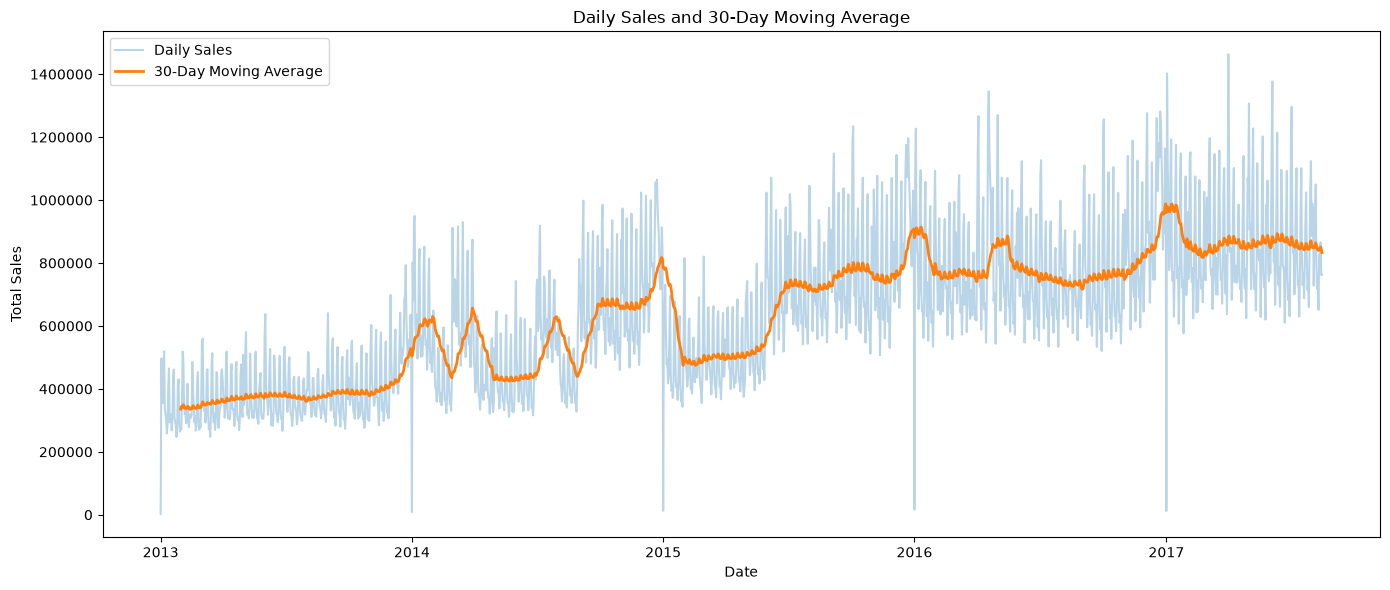

In [4]:
# Aggregate daily sales
daily_sales = (
    df.groupby("date")["sales"]
    .sum()
    .sort_index()
)

# Smooth fluctuations using a 30-day moving average
rolling_sales = daily_sales.rolling(window=30).mean()

plt.figure(figsize=(14, 6))

plt.plot(
    daily_sales.index,
    daily_sales.values,
    alpha=0.3,
    label="Daily Sales"
)

plt.plot(
    rolling_sales.index,
    rolling_sales.values,
    linewidth=2,
    label="30-Day Moving Average"
)

plt.title("Daily Sales and 30-Day Moving Average")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.ticklabel_format(
    style="plain",
    axis="y"
)
plt.legend()
plt.tight_layout()
plt.show()

In [5]:
print(daily_sales.nsmallest(10))
zero_sales_pct = (df["sales"] == 0).mean() * 100
print(f"Zero sales: {zero_sales_pct:.2f}%")
top_families = (
    df.groupby("family")["sales"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

print(top_families)

date
2013-01-01      2511.618999
2014-01-01      8602.065404
2017-01-01     12082.500997
2015-01-01     12773.616980
2016-01-01     16433.394000
2013-01-24    247245.690995
2013-03-14    247541.420096
2013-01-10    258982.003049
2013-01-29    264488.818076
2013-06-27    266525.458966
Name: sales, dtype: float64
Zero sales: 31.30%
family
GROCERY I    3.434627e+08
BEVERAGES    2.169545e+08
PRODUCE      1.227047e+08
CLEANING     9.752129e+07
DAIRY        6.448771e+07
Name: sales, dtype: float64


In [6]:

df = df.sort_values(
    ["store_nbr", "family", "date"]
).copy()

df.head()

groups = df.groupby(
    ["store_nbr", "family"]
)
df["sales_lag_1"]=(groups["sales"].shift(1))
df["sales_lag_7"]=(groups["sales"].shift(7))
df["sales_lag_14"]=(groups["sales"].shift(14))

columns = [
    "date",
    "store_nbr",
    "family",
    "sales",
    "sales_lag_1",
    "sales_lag_7",
    "sales_lag_14"
]

print(
    df.loc[
        (df["store_nbr"] == 1) &
        (df["family"] == "GROCERY I"),
        columns
    ].head(20).to_string(index=False)
)


      date  store_nbr    family  sales  sales_lag_1  sales_lag_7  sales_lag_14
2013-01-01          1 GROCERY I    0.0          NaN          NaN           NaN
2013-01-02          1 GROCERY I 2652.0          0.0          NaN           NaN
2013-01-03          1 GROCERY I 2121.0       2652.0          NaN           NaN
2013-01-04          1 GROCERY I 2056.0       2121.0          NaN           NaN
2013-01-05          1 GROCERY I 2216.0       2056.0          NaN           NaN
2013-01-06          1 GROCERY I  723.0       2216.0          NaN           NaN
2013-01-07          1 GROCERY I 2262.0        723.0          NaN           NaN
2013-01-08          1 GROCERY I 1782.0       2262.0          0.0           NaN
2013-01-09          1 GROCERY I 2429.0       1782.0       2652.0           NaN
2013-01-10          1 GROCERY I 1544.0       2429.0       2121.0           NaN
2013-01-11          1 GROCERY I 1750.0       1544.0       2056.0           NaN
2013-01-12          1 GROCERY I 1796.0       1750.0 

In [7]:
date_gaps = (
    df.groupby(["store_nbr", "family"])["date"]
      .diff()
      .dropna()
)

print("Non-daily gaps:", (date_gaps != pd.Timedelta(days=1)).sum())

Non-daily gaps: 7128


In [8]:

# Calculate the difference between consecutive dates
df["date_gap"] = (
    df.groupby(["store_nbr", "family"])["date"]
      .diff()
)

# Find observations where the gap exceeds one day
gaps = df[
    df["date_gap"] > pd.Timedelta(days=1)
]

print("Total gaps:", len(gaps))

# See how large the gaps are
print(gaps["date_gap"].value_counts().head(10))

# Inspect examples
print(
    gaps[
        ["date", "store_nbr", "family", "date_gap"]
    ].head(15).to_string(index=False)
)

Total gaps: 7128
date_gap
2 days    7128
Name: count, dtype: int64
      date  store_nbr     family date_gap
2013-12-26          1 AUTOMOTIVE   2 days
2014-12-26          1 AUTOMOTIVE   2 days
2015-12-26          1 AUTOMOTIVE   2 days
2016-12-26          1 AUTOMOTIVE   2 days
2013-12-26          1  BABY CARE   2 days
2014-12-26          1  BABY CARE   2 days
2015-12-26          1  BABY CARE   2 days
2016-12-26          1  BABY CARE   2 days
2013-12-26          1     BEAUTY   2 days
2014-12-26          1     BEAUTY   2 days
2015-12-26          1     BEAUTY   2 days
2016-12-26          1     BEAUTY   2 days
2013-12-26          1  BEVERAGES   2 days
2014-12-26          1  BEVERAGES   2 days
2015-12-26          1  BEVERAGES   2 days


In [9]:

all_dates = pd.date_range(
    start=df["date"].min(),
    end=df["date"].max(),
    freq="D"
)

missing_dates = all_dates.difference(
    df["date"].unique()
)

print("Missing dates:", len(missing_dates))
print(missing_dates)

Missing dates: 4
DatetimeIndex(['2013-12-25', '2014-12-25', '2015-12-25', '2016-12-25'],
              dtype='datetime64[us]', freq=None)


In [10]:
historical7 = df[
    ["date", "store_nbr", "family", "sales"]
].copy()

historical7["date"] += pd.Timedelta(days=7)

historical7 = historical7.rename(
    columns={"sales": "sales_lag_7"}
)

historical1 = df[
    ["date", "store_nbr", "family", "sales"]
].copy()

historical1["date"] += pd.Timedelta(days=1)

historical1 = historical1.rename(
    columns={"sales": "sales_lag_1"})

historical14 = df[
    ["date", "store_nbr", "family", "sales"]
].copy()

historical14["date"] += pd.Timedelta(days=14)

historical14 = historical14.rename(
    columns={"sales": "sales_lag_14"})

In [11]:
df = df.drop(
    columns=["sales_lag_1", "sales_lag_7", "sales_lag_14"],
    errors="ignore"
)

In [12]:
df = df.merge(
    historical7,
    on=["date", "store_nbr", "family"],
    how="left",
    validate="one_to_one"
)
df = df.merge(
    historical14,
    on=["date", "store_nbr", "family"],
    how="left",
    validate="one_to_one"
)
df = df.merge(
    historical1,
    on=["date", "store_nbr", "family"],
    how="left",
    validate="one_to_one"
)

In [13]:
check = df.loc[
    (df["store_nbr"] == 1) &
    (df["family"] == "GROCERY I") &
    (df["date"].between("2013-12-24", "2013-12-28")),
    ["date", "sales", "sales_lag_1", "sales_lag_7", "sales_lag_14"]
]

print(check.to_string(index=False))

      date  sales  sales_lag_1  sales_lag_7  sales_lag_14
2013-12-24 3036.0       4367.0       2713.0        2835.0
2013-12-26 2052.0          NaN       3030.0        3660.0
2013-12-27 2152.0       2052.0       3972.0        2546.0
2013-12-28 1323.0       2152.0       2916.0        2331.0


In [14]:
def add_rolling_features(group):
    group = group.sort_values("date").copy()

    # Use dates as the index for time-based rolling
    sales_by_date = group.set_index("date")["sales"]

    # Exclude the current date
    previous_sales = sales_by_date.shift(
        freq="D"
    )

    # Average sales over the previous 7 calendar days
    rolling_mean = previous_sales.rolling("7D").mean()

    # Align calculated values back to the original dates
    group["rolling_mean_7"] = rolling_mean.reindex(
        group["date"]
    ).to_numpy()

    return group


In [15]:
for lag in range(1, 8):
    column = f"sales_lag_{lag}"
  
      
    if not isinstance(df, pd.DataFrame):
        raise RuntimeError("df must be initialized as a pandas DataFrame")

    df_columns = set(df.columns)
    

    if column not in df_columns:
        historical = df[
            ["date", "store_nbr", "family", "sales"]
        ].copy()

        historical["date"] += pd.Timedelta(days=lag)
        print(historical["date"])
        historical = historical.rename(
            columns={"sales": column}
        )

        df = df.merge(
            historical,
            on=["date", "store_nbr", "family"],
            how="left",
            validate="one_to_one"
        )

lag_columns = [
    f"sales_lag_{lag}"
    for lag in range(1, 8)
]

df["rolling_mean_7"] = (
    df[lag_columns].mean(axis=1)
)
df["rolling_count_7"] = df[lag_columns].count(axis=1)
print(df["rolling_mean_7"])
df.tail()


0         2013-01-03
1         2013-01-04
2         2013-01-05
3         2013-01-06
4         2013-01-07
             ...    
3000883   2017-08-13
3000884   2017-08-14
3000885   2017-08-15
3000886   2017-08-16
3000887   2017-08-17
Name: date, Length: 3000888, dtype: datetime64[us]
0         2013-01-04
1         2013-01-05
2         2013-01-06
3         2013-01-07
4         2013-01-08
             ...    
3000883   2017-08-14
3000884   2017-08-15
3000885   2017-08-16
3000886   2017-08-17
3000887   2017-08-18
Name: date, Length: 3000888, dtype: datetime64[us]
0         2013-01-05
1         2013-01-06
2         2013-01-07
3         2013-01-08
4         2013-01-09
             ...    
3000883   2017-08-15
3000884   2017-08-16
3000885   2017-08-17
3000886   2017-08-18
3000887   2017-08-19
Name: date, Length: 3000888, dtype: datetime64[us]
0         2013-01-06
1         2013-01-07
2         2013-01-08
3         2013-01-09
4         2013-01-10
             ...    
3000883   2017-08-16
3000884

,id,date,store_nbr,family,sales,onpromotion,date_gap,sales_lag_7,sales_lag_14,sales_lag_1,sales_lag_2,sales_lag_3,sales_lag_4,sales_lag_5,sales_lag_6,rolling_mean_7,rolling_count_7
3000883,2993627,2017-08-11,54,SEAFOOD,0.0,0,1 days,0.0,4.0,2.0,4.0,12.0,0.0,0.0,3.0,3.000000,7
3000884,2995409,2017-08-12,54,SEAFOOD,1.0,1,1 days,3.0,4.0,0.0,2.0,4.0,12.0,0.0,0.0,3.000000,7
3000885,2997191,2017-08-13,54,SEAFOOD,2.0,0,1 days,0.0,4.0,1.0,0.0,2.0,4.0,12.0,0.0,2.714286,7
3000886,2998973,2017-08-14,54,SEAFOOD,0.0,0,1 days,0.0,4.0,2.0,1.0,0.0,2.0,4.0,12.0,3.000000,7
3000887,3000755,2017-08-15,54,SEAFOOD,3.0,0,1 days,12.0,3.0,0.0,2.0,1.0,0.0,2.0,4.0,3.000000,7


In [16]:
print(
    df.loc[
        (df["store_nbr"] == 1) &
        (df["family"] == "GROCERY I") &
        (df["date"].between("2013-12-24", "2013-12-28")),
        ["date", "sales", "rolling_mean_7", "rolling_count_7"]
    ].to_string(index=False)
)

      date  sales  rolling_mean_7  rolling_count_7
2013-12-24 3036.0     3262.285714                7
2013-12-26 2052.0     3242.833333                6
2013-12-27 2152.0     3079.833333                6
2013-12-28 1323.0     2776.500000                6


In [17]:
df["day_of_week"] = df["date"].dt.dayofweek


df["month"] = df["date"].dt.month

df["day_of_year"] = df["date"].dt.dayofyear

df["is_weekend"] = df["day_of_week"].isin([5, 6]).astype(int)
df.head()


C:\Users\madde\AppData\Local\Temp\ipykernel_30916\3802434044.py:1: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["day_of_week"] = df["date"].dt.dayofweek
C:\Users\madde\AppData\Local\Temp\ipykernel_30916\3802434044.py:6: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  df["day_of_year"] = df["date"].dt.dayofyear


,id,date,store_nbr,family,sales,onpromotion,date_gap,sales_lag_7,sales_lag_14,sales_lag_1,...,sales_lag_3,sales_lag_4,sales_lag_5,sales_lag_6,rolling_mean_7,rolling_count_7,day_of_week,month,day_of_year,is_weekend
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,NaT,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0,1,1,1,0
1,1782,2013-01-02,1,AUTOMOTIVE,2.0,0,1 days,NaN,NaN,0.0,...,NaN,NaN,NaN,NaN,0.000000,1,2,1,2,0
2,3564,2013-01-03,1,AUTOMOTIVE,3.0,0,1 days,NaN,NaN,2.0,...,NaN,NaN,NaN,NaN,1.000000,2,3,1,3,0
3,5346,2013-01-04,1,AUTOMOTIVE,3.0,0,1 days,NaN,NaN,3.0,...,0.0,NaN,NaN,NaN,1.666667,3,4,1,4,0
4,7128,2013-01-05,1,AUTOMOTIVE,5.0,0,1 days,NaN,NaN,3.0,...,2.0,0.0,NaN,NaN,2.000000,4,5,1,5,1


In [18]:
print(
    df.loc[
        (df["store_nbr"] == 1) &
        (df["family"] == "GROCERY I") &
        (df["date"].between("2013-12-23", "2013-12-29")),
        [
            "date",
            "day_of_week",
            "month",
            "day_of_year",
            "is_weekend"
        ]
    ].to_string(index=False)
)


      date  day_of_week  month  day_of_year  is_weekend
2013-12-23            0     12          357           0
2013-12-24            1     12          358           0
2013-12-26            3     12          360           0
2013-12-27            4     12          361           0
2013-12-28            5     12          362           1
2013-12-29            6     12          363           1


In [19]:
target = "sales"
features = [
    "store_nbr",
    "family",
    "day_of_week",
    "month",
    "day_of_year",
    "is_weekend",
    "sales_lag_1",
    "sales_lag_7",
    "sales_lag_14",
    "rolling_mean_7",
    "rolling_count_7"
]
print("Dataset shape:", df.shape)

print("\nMissing values in model features:")
print(df[features].isna().sum())

print("\nFeature data types:")
print(df[features].dtypes)


Dataset shape: (3000888, 21)

Missing values in model features:
store_nbr              0
family                 0
day_of_week            0
month                  0
day_of_year            0
is_weekend             0
sales_lag_1         8910
sales_lag_7        19602
sales_lag_14       32076
rolling_mean_7      1782
rolling_count_7        0
dtype: int64

Feature data types:
store_nbr            int64
family                 str
day_of_week          int32
month                int32
day_of_year          int32
is_weekend           int64
sales_lag_1        float64
sales_lag_7        float64
sales_lag_14       float64
rolling_mean_7     float64
rolling_count_7      int64
dtype: object


In [20]:

required_lags = [
    "sales_lag_1",
    "sales_lag_7",
    "sales_lag_14"
]

model_df = df.dropna(
    subset=required_lags + ["rolling_mean_7"]
).copy()

print("Original rows:", len(df))
print("Model-ready rows:", len(model_df))

print(
    "Rows removed:",
    len(df) - len(model_df)
)

print(
    "\nRemaining missing values:",
    model_df[features].isna().sum().sum()
)


Original rows: 3000888
Model-ready rows: 2954556
Rows removed: 46332

Remaining missing values: 0


In [21]:

split_date = "2017-01-01"

train_df = model_df[
    model_df["date"] < split_date
].copy()

val_df = model_df[
    model_df["date"] >= split_date
].copy()

print("Training rows:", len(train_df))
print("Validation rows:", len(val_df))

print("Training dates:",
      train_df["date"].min(),
      train_df["date"].max())

print("Validation dates:",
      val_df["date"].min(),
      val_df["date"].max())

Training rows: 2553606
Validation rows: 400950
Training dates: 2013-01-15 00:00:00 2016-12-31 00:00:00
Validation dates: 2017-01-02 00:00:00 2017-08-15 00:00:00


In [22]:

# Actual sales
y_val = val_df["sales"]

# Seasonal-naive predictions
baseline_predictions = val_df["sales_lag_7"]

print("Actual sales:")
print(y_val.head())

print("\nBaseline predictions:")
print(baseline_predictions.head())

Actual sales:
1458    5.0
1459    4.0
1460    1.0
1461    2.0
1462    2.0
Name: sales, dtype: float64

Baseline predictions:
1458     0.0
1459     5.0
1460    12.0
1461     3.0
1462     4.0
Name: sales_lag_7, dtype: float64


In [23]:
from sklearn.metrics import mean_absolute_error

baseline_mae = mean_absolute_error(
    y_val,
    baseline_predictions
)

print(f"Baseline MAE: {baseline_mae:.2f}")

Baseline MAE: 94.27
